<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Hierarchical Clustering
## Tugas Lab 1 - Agglomerative Clustering pada Data Nasabah Kartu Kredit

Dataset: `CC_Customer_Dataset.csv` (dataset Tugas Lab JS07).

**Soal**
1. Buat model *Agglomerative Clustering* dengan **semua variabel yang dapat digunakan** dari dataset.
2. Buat *scatter plot* dengan dua variabel, `Avg_Credit_Limit` dan `Total_credit_card`, lalu tunjukkan bentuk *cluster* berdasarkan kedua fitur tersebut.
3. Hitung nilai *silhouette score* dan *Davies-Bouldin Index* (DBI) dari model.

## Persiapan - Import Library dan Load Dataset

Sel berikut mencari file `.csv` yang memiliki kolom `Avg_Credit_Limit` di folder kerja (nama file bisa `CC_Customer_Dataset.csv` atau nama lain). Jika tidak ditemukan dan memakai Colab, dialog upload akan muncul.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_style('whitegrid')


def cari_csv():
    for f in glob.glob('*.csv'):
        try:
            if 'Avg_Credit_Limit' in pd.read_csv(f, nrows=1).columns:
                return f
        except Exception:
            pass
    return None


path = cari_csv()
if path is None:
    try:
        from google.colab import files
        print('Silakan upload file CC_Customer_Dataset.csv')
        files.upload()
        path = cari_csv()
    except ImportError:
        pass

if path is None:
    raise FileNotFoundError('Dataset tidak ditemukan. Letakkan CC_Customer_Dataset.csv (kolom Avg_Credit_Limit) di folder yang sama dengan notebook ini.')

df = pd.read_csv(path)
print('File dataset :', path)
print('Ukuran data  :', df.shape)
df.head()

Silakan upload file CC_Customer_Dataset.csv


Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv
File dataset : CC_Customer_Dataset.csv
Ukuran data  : (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
df.info()
print()
print('Missing values:', int(df.isna().sum().sum()), '| Baris duplikat:', int(df.duplicated().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Missing values: 0 | Baris duplikat: 0


In [3]:
col_limit = next(c for c in df.columns if c.lower() == 'avg_credit_limit')
col_cards = next(c for c in df.columns if c.lower().startswith('total_credit_card'))

# Kolom identitas bukan ciri nasabah -> tidak dipakai
kolom_id = [c for c in df.columns if c.lower() in ('sl_no', 'customer key', 'customer_key')]
fitur_semua = [c for c in df.select_dtypes(include='number').columns if c not in kolom_id]

print('Kolom limit kredit :', col_limit)
print('Kolom jumlah kartu :', col_cards)
print('Kolom identitas    :', kolom_id, '(tidak dipakai)')
print('Fitur yang dipakai :', fitur_semua)

Kolom limit kredit : Avg_Credit_Limit
Kolom jumlah kartu : Total_Credit_Cards
Kolom identitas    : ['Sl_No', 'Customer Key'] (tidak dipakai)
Fitur yang dipakai : ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


## Soal 1 - Model Agglomerative Clustering dengan Semua Variabel

Seluruh variabel numerik (di luar kolom identitas) dipakai. Karena klasterisasi hierarkis berbasis **jarak**, fitur diskalakan dengan `StandardScaler` agar `Avg_Credit_Limit` (puluhan ribu) tidak mendominasi fitur lain yang bernilai kecil.

Jumlah *cluster* ditentukan dari dendrogram (Ward) dan dibandingkan dengan *silhouette score* untuk beberapa nilai $k$.

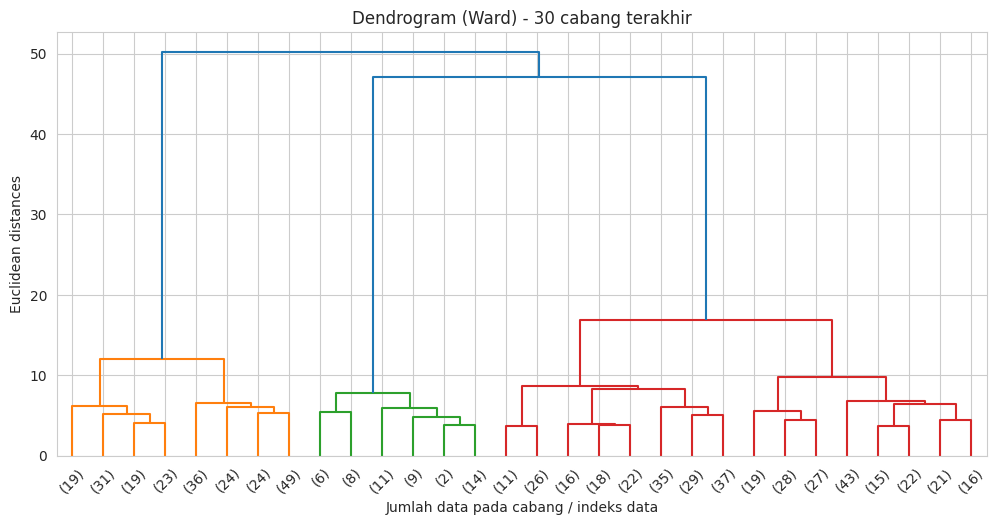

In [4]:
X = StandardScaler().fit_transform(df[fitur_semua].values)

Z = sch.linkage(X, method='ward')
plt.figure(figsize=(12, 5.5))
sch.dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogram (Ward) - 30 cabang terakhir')
plt.xlabel('Jumlah data pada cabang / indeks data')
plt.ylabel('Euclidean distances')
plt.show()

Jarak penggabungan terakhir dan lonjakan (gap) untuk memotong menjadi k cluster:
 k | penggabungan (k -> k-1) pada jarak | gap potong k cluster
 2 |                             50.163 |                3.096
 3 |                             47.067 |               30.222
 4 |                             16.845 |                4.837
 5 |                             12.008 |                2.266
 6 |                              9.742 |                1.146
 7 |                              8.596 |                0.276
 8 |                              8.320 |                0.523
 9 |                              7.797 |                0.984
10 |                              6.813 |                0.314

 k  silhouette      DBI
 2    0.417704 0.932640
 3    0.514764 0.680960
 4    0.348082 1.149303
 5    0.256918 1.385112
 6    0.226778 1.410876
 7    0.216297 1.439434
 8    0.218695 1.448888
 9    0.195271 1.546620
10    0.193142 1.553695


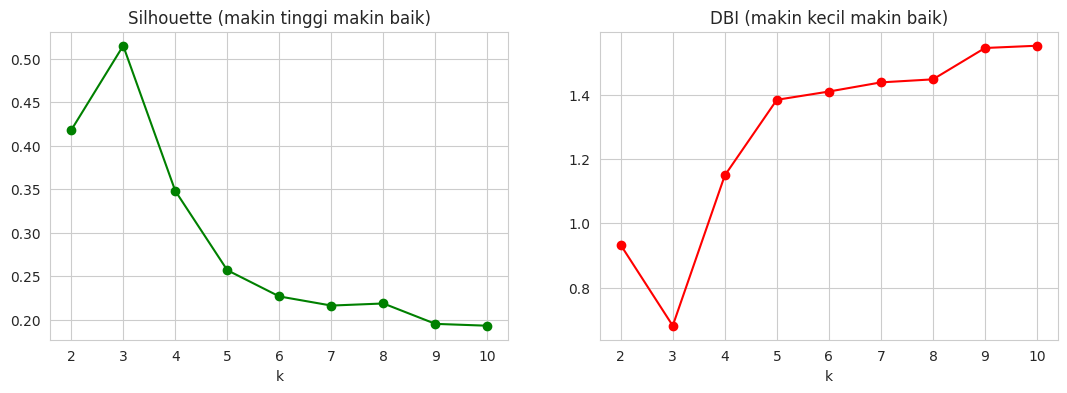

In [5]:
# Jarak penggabungan terakhir. Lonjakan besar antar penggabungan menandakan titik potong yang wajar:
# memotong di antara dua penggabungan yang jaraknya berjauhan menghasilkan k cluster yang stabil.
h = Z[::-1, 2]                                   # jarak penggabungan, dari yang terbesar
print('Jarak penggabungan terakhir dan lonjakan (gap) untuk memotong menjadi k cluster:')
print(' k | penggabungan (k -> k-1) pada jarak | gap potong k cluster')
for k in range(2, 11):
    print(f'{k:>2} | {h[k - 2]:>34.3f} | {h[k - 2] - h[k - 1]:>20.3f}')

# Silhouette dan DBI untuk k = 2..10
baris = []
for k in range(2, 11):
    lbl = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward').fit_predict(X)
    baris.append({'k': k, 'silhouette': silhouette_score(X, lbl), 'DBI': davies_bouldin_score(X, lbl)})
tabel_k = pd.DataFrame(baris)
print()
print(tabel_k.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(tabel_k['k'], tabel_k['silhouette'], 'go-'); ax[0].set_title('Silhouette (makin tinggi makin baik)')
ax[1].plot(tabel_k['k'], tabel_k['DBI'], 'ro-'); ax[1].set_title('DBI (makin kecil makin baik)')
for a in ax:
    a.set_xlabel('k')
plt.show()

In [6]:
# k dipilih berdasarkan silhouette tertinggi (DBI dan lonjakan dendrogram sebagai pembanding).
# Jika hasil dendrogram dan silhouette berbeda, Anda dapat mengganti k_terbaik secara manual
# dan menjelaskan alasannya pada analisis.
k_silhouette = int(tabel_k.loc[tabel_k['silhouette'].idxmax(), 'k'])
k_dbi = int(tabel_k.loc[tabel_k['DBI'].idxmin(), 'k'])
k_gap = max(range(2, 11), key=lambda k: h[k - 2] - h[k - 1])
print('k terbaik menurut silhouette      :', k_silhouette)
print('k terbaik menurut DBI             :', k_dbi)
print('k dengan lonjakan dendrogram terbesar:', k_gap)

k_terbaik = k_silhouette
print('k terpilih:', k_terbaik)

model = AgglomerativeClustering(n_clusters=k_terbaik, metric='euclidean', linkage='ward')
df['cluster'] = model.fit_predict(X)
print(df['cluster'].value_counts().sort_index())

k terbaik menurut silhouette      : 3
k terbaik menurut DBI             : 3
k dengan lonjakan dendrogram terbesar: 3
k terpilih: 3
cluster
0    385
1    225
2     50
Name: count, dtype: int64


In [7]:
# Profil tiap cluster (rata-rata fitur pada skala asli)
profil = df.groupby('cluster')[fitur_semua].mean().round(2)
profil['jumlah_nasabah'] = df['cluster'].value_counts().sort_index()
profil

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster,,,,,,
0,33851.95,5.52,3.49,0.98,1.99,385
1,12151.11,2.42,0.94,3.55,6.86,225
2,141040.00,8.74,0.60,10.90,1.08,50


## Soal 2 - Scatter Plot `Avg_Credit_Limit` vs `Total_credit_card`

Hasil klasterisasi (yang dilatih dari **semua** variabel) digambarkan pada dua variabel saja agar dapat divisualisasikan.

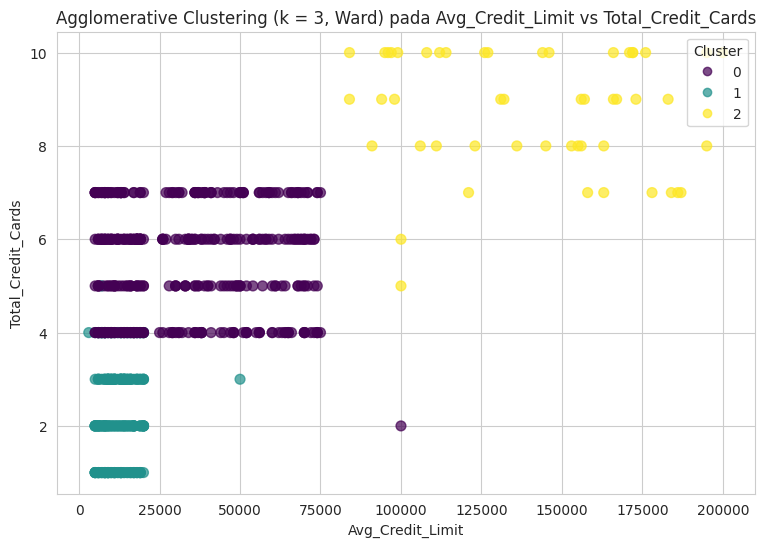

In [8]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(df[col_limit], df[col_cards], c=df['cluster'], cmap='viridis', s=50, alpha=0.7)
plt.xlabel(col_limit)
plt.ylabel(col_cards)
plt.title(f'Agglomerative Clustering (k = {k_terbaik}, Ward) pada {col_limit} vs {col_cards}')
plt.legend(*sc.legend_elements(), title='Cluster', loc='upper right')
plt.show()

> **Catatan membaca grafik:** model dilatih memakai semua fitur, sedangkan grafik hanya menampilkan 2 fitur. Karena itu *cluster* yang sebenarnya terpisah pada fitur lain (misalnya kunjungan bank/online dan panggilan) dapat tampak bertumpuk pada grafik ini. Hal ini wajar dan bukan kesalahan model.

## Soal 3 - Silhouette Score dan Davies-Bouldin Index

In [9]:
sil = silhouette_score(X, df['cluster'])
dbi = davies_bouldin_score(X, df['cluster'])
print(f'Jumlah cluster       : {k_terbaik}')
print(f'Silhouette score     : {sil:.4f}   (makin dekat +1 makin baik)')
print(f'Davies-Bouldin Index : {dbi:.4f}   (makin kecil makin baik)')

Jumlah cluster       : 3
Silhouette score     : 0.5148   (makin dekat +1 makin baik)
Davies-Bouldin Index : 0.6810   (makin kecil makin baik)


### Analisis

- Jumlah *cluster* dipilih dari *silhouette* tertinggi dan dibandingkan dengan DBI serta lonjakan dendrogram. Jika ketiganya tidak sepakat, jelaskan alasan pemilihan $k$ Anda (misalnya $k=2$ sering unggul pada *silhouette* karena hanya memisahkan dua kelompok terbesar, tetapi kurang informatif untuk segmentasi).
- *Silhouette score* mendekati +1 berarti titik dekat dengan *cluster*-nya sendiri dan jauh dari *cluster* lain; mendekati 0 berarti *cluster* tumpang tindih.
- DBI makin kecil berarti *cluster* makin padat dan terpisah.
- Skor dihitung pada data yang sudah diskalakan (ruang fitur yang dipakai model), bukan pada skala asli.
- Interpretasi *cluster* (profil nasabah) dapat dibaca dari tabel profil di atas.